# 02 — Descriptive and Distributional Analysis

This notebook describes the distributions and coverage of core indicators. The aim is to understand the data before interpreting country differences or testing relationships.

> **Reading guide:** Each analysis section follows the same pattern: question → method → code → interpretation. The conclusion directly below each major code block explains what the output means and what it does *not* establish.

## 1. Analytical scope

**Question.** How are the main energy indicators distributed across observed entity–year records?

I start with a curated set of indicators that represent economic scale, energy use, renewable electricity, fossil electricity and carbon intensity. I report valid counts because missingness differs by variable.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "owid_energy.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
DATA_PATH = PROJECT_ROOT / "data" / "owid_energy.csv"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5.5)
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["savefig.dpi"] = 160

raw = pd.read_csv(DATA_PATH, low_memory=False)
df = raw.copy()
print(f"Loaded {DATA_PATH.name}: {df.shape[0]:,} rows × {df.shape[1]:,} columns")

candidate_metrics = [
    "population", "gdp", "total_energy_twh", "total_energy_per_capita_kwh",
    "total_energy_per_gdp_kwh_per_dollar", "electricity_generation_twh",
    "renewables_electricity_share_pct", "fossil_fuels_electricity_share_pct",
    "electricity_carbon_intensity_gco2eq_per_kwh"
]
metrics = [c for c in candidate_metrics if c in df.columns]
summary = df[metrics].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T
summary["missing_pct"] = df[metrics].isna().mean() * 100
summary["skewness"] = df[metrics].skew(numeric_only=True)
summary["kurtosis"] = df[metrics].kurtosis(numeric_only=True)
summary.to_csv(TABLE_DIR / "descriptive_statistics.csv")
display(summary.round(3))

Loaded owid_energy.csv: 19,494 rows × 130 columns


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,missing_pct,skewness,kurtosis
population,18319.0,9.420242e+07,4.728772e+08,1.776000e+03,6.382980e+03,5.688150e+04,1.511983e+06,6.613368e+06,2.233644e+07,3.223180e+08,2.338202e+09,8.231613e+09,6.027,9.488,111.790
gdp,11834.0,4.252797e+11,3.499917e+12,1.642060e+08,4.776039e+08,2.168265e+09,1.450994e+10,4.458353e+10,1.845872e+11,1.432138e+12,4.737022e+12,1.301126e+14,39.294,28.735,938.856
total_energy_twh,11848.0,3.010549e+03,1.174276e+04,0.000000e+00,0.000000e+00,2.880000e-01,6.379000e+00,6.143800e+01,5.174760e+02,1.928617e+04,6.459905e+04,1.667536e+05,39.222,6.698,57.694
total_energy_per_capita_kwh,11281.0,2.513428e+04,3.781050e+04,0.000000e+00,0.000000e+00,3.510460e+02,2.890740e+03,1.253242e+04,3.524648e+04,8.448794e+04,1.811733e+05,6.518366e+05,42.131,4.909,45.578
total_energy_per_gdp_kwh_per_dollar,7884.0,1.638000e+00,1.624000e+00,7.800000e-02,1.800000e-01,3.160000e-01,7.580000e-01,1.185000e+00,2.005000e+00,4.385000e+00,7.182000e+00,2.525300e+01,59.557,4.880,42.902
electricity_generation_twh,7871.0,7.895490e+02,2.633347e+03,0.000000e+00,1.000000e-02,1.000000e-01,2.190000e+00,2.182000e+01,1.696700e+02,4.866750e+03,1.300829e+04,3.177235e+04,59.623,5.389,36.174
renewables_electricity_share_pct,7615.0,2.930800e+01,3.020800e+01,0.000000e+00,0.000000e+00,0.000000e+00,3.462000e+00,1.836100e+01,4.762200e+01,9.741400e+01,1.000000e+02,1.000000e+02,60.937,0.996,-0.170
fossil_fuels_electricity_share_pct,7315.0,6.504700e+01,3.102600e+01,0.000000e+00,0.000000e+00,2.176000e+00,4.316000e+01,7.091100e+01,9.427700e+01,1.000000e+02,1.000000e+02,1.000000e+02,62.476,-0.631,-0.731
electricity_carbon_intensity_gco2eq_per_kwh,6332.0,4.771590e+02,2.414380e+02,0.000000e+00,2.339600e+01,3.345700e+01,2.977850e+02,5.238100e+02,6.500000e+02,8.263570e+02,1.000000e+03,1.306720e+03,67.518,-0.126,-0.192


### Conclusion

Use the median and percentiles alongside the mean: country-level energy and economic variables are typically right-skewed because countries differ greatly in population and economic scale. The valid count and missingness columns are part of the result, not footnotes. These pooled summaries mix countries and years, so they describe the file rather than a single representative country.

## 2. Distribution of scale variables

**Question.** Are large energy and economic values concentrated in a small number of observations?

For positive, strongly skewed scale variables, I use logarithmic x-axes to make the distribution visible without implying that the underlying values have been changed.

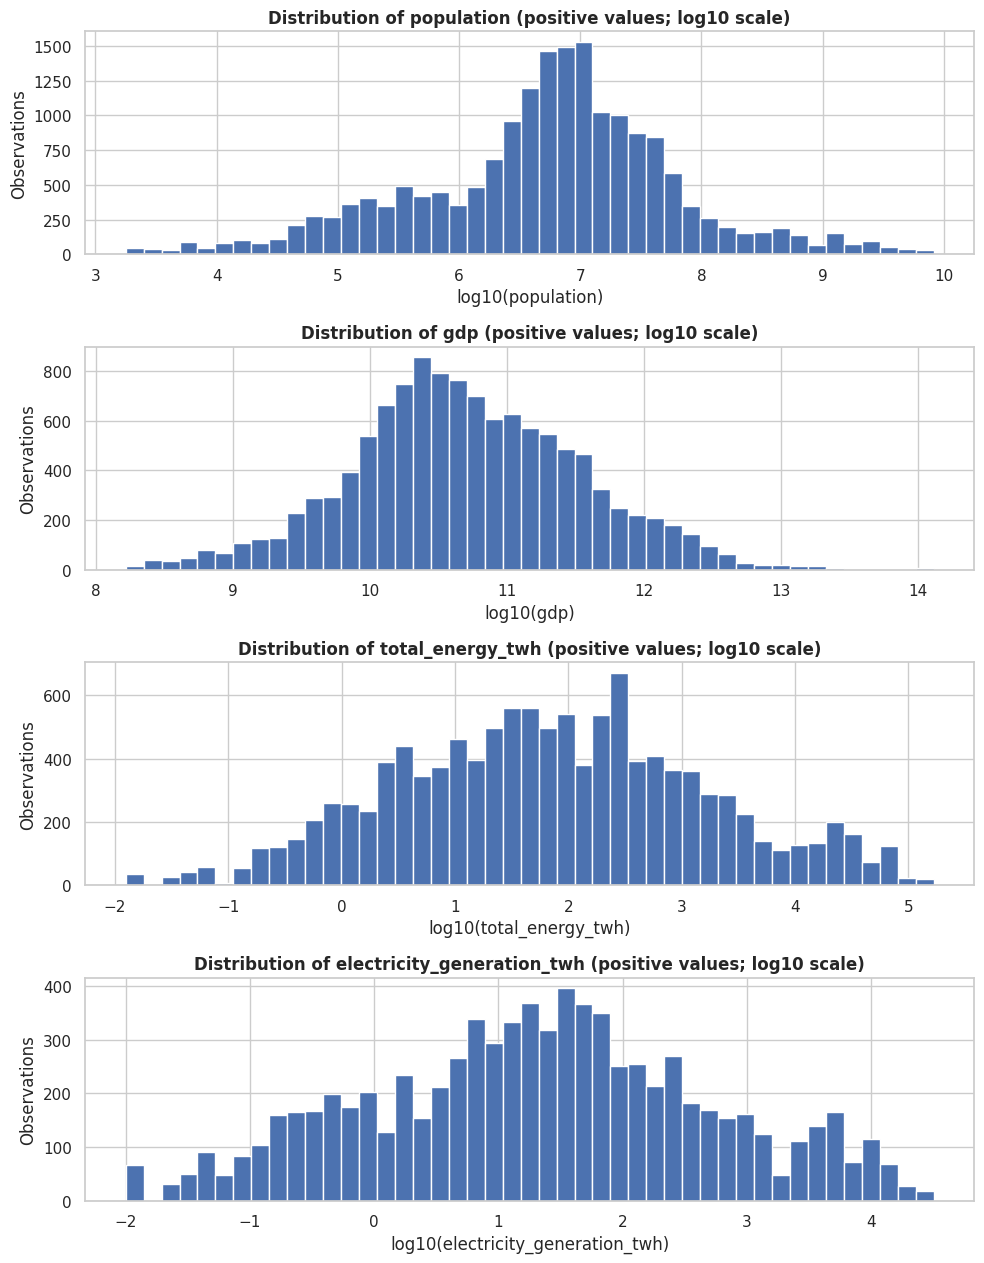

In [2]:
scale_metrics = [c for c in ["population", "gdp", "total_energy_twh", "electricity_generation_twh"] if c in df.columns]
fig, axes = plt.subplots(len(scale_metrics), 1, figsize=(10, 3.2 * len(scale_metrics)))
if len(scale_metrics) == 1: axes = [axes]
for ax, col in zip(axes, scale_metrics):
    vals = pd.to_numeric(df[col], errors="coerce")
    vals = vals[vals > 0].dropna()
    ax.hist(np.log10(vals), bins=45, edgecolor="white")
    ax.set_title(f"Distribution of {col} (positive values; log10 scale)")
    ax.set_xlabel(f"log10({col})")
    ax.set_ylabel("Observations")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "03_scale_variable_distributions.png", bbox_inches="tight")
plt.show()

### Conclusion

A log scale helps compare orders of magnitude; it does not make the data normally distributed or justify treating differences as additive. Zero and negative values are omitted from these positive-only plots and remain in the source data. Interpret the distribution together with the country/year mix and the descriptive table.

## 3. Per-capita energy and carbon indicators

**Question.** How much variation exists after moving beyond absolute scale?

Per-capita and intensity metrics are useful complements to totals, but they answer different questions: per-capita energy measures average use per person, while energy intensity relates energy to economic output.

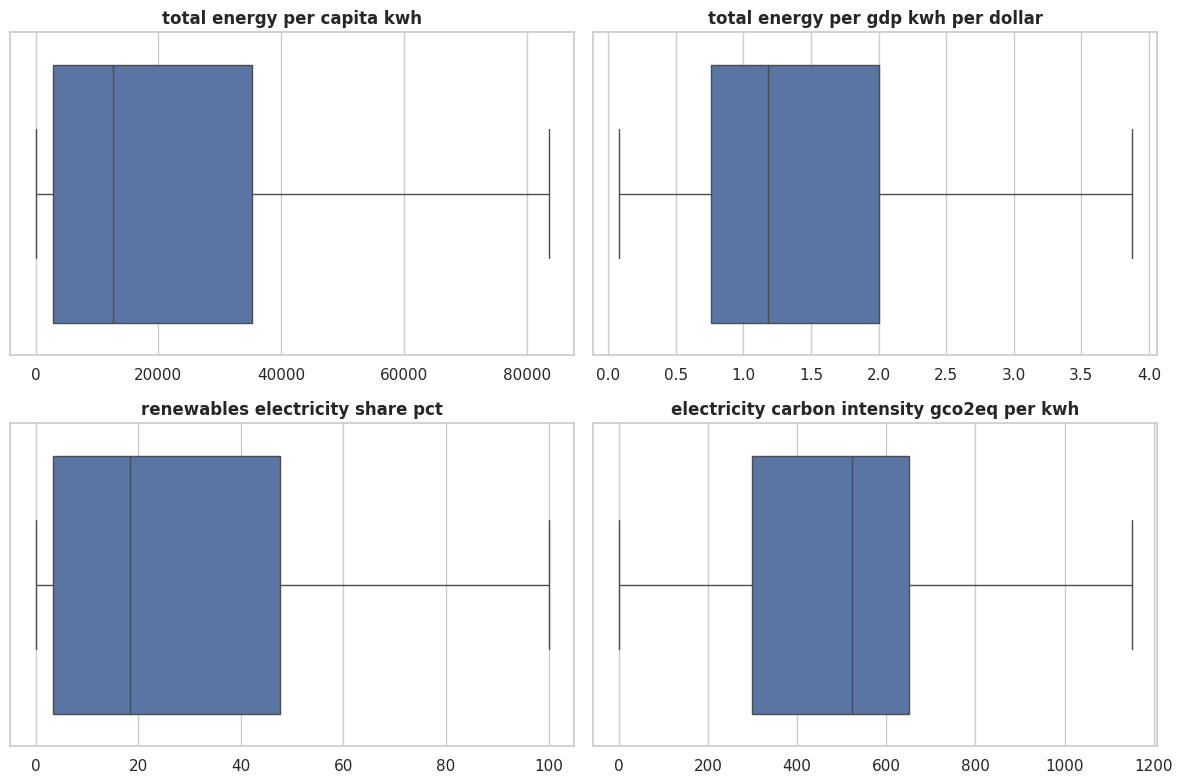

In [3]:
compare_metrics = [c for c in ["total_energy_per_capita_kwh", "total_energy_per_gdp_kwh_per_dollar",
                               "renewables_electricity_share_pct", "electricity_carbon_intensity_gco2eq_per_kwh"] if c in df.columns]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, col in zip(axes.flat, compare_metrics):
    sns.boxplot(x=pd.to_numeric(df[col], errors="coerce"), ax=ax, showfliers=False)
    ax.set_title(col.replace("_", " "))
    ax.set_xlabel("")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "04_per_capita_intensity_and_share_boxplots.png", bbox_inches="tight")
plt.show()

### Conclusion

Boxplots make medians and central spreads visible, while hiding plotted outlier markers here to keep the central distribution readable. This is a visualization choice only; no observations are removed from the dataset. The metrics have different units and should not be compared by raw numeric magnitude.

## 4. Coverage threshold sensitivity

**Question.** How many observations remain when I require more complete reporting for a focused set of indicators?

I compare the available sample sizes rather than automatically dropping rows across all 130 variables.

In [4]:
coverage_table = pd.DataFrame({
    "indicator": metrics,
    "non_missing_n": [int(df[c].notna().sum()) for c in metrics],
    "non_missing_pct": [round(df[c].notna().mean() * 100, 2) for c in metrics]
}).sort_values("non_missing_pct", ascending=False)
coverage_table.to_csv(TABLE_DIR / "indicator_coverage.csv", index=False)
display(coverage_table)

,indicator,non_missing_n,non_missing_pct
0,population,18319,93.97
2,total_energy_twh,11848,60.78
1,gdp,11834,60.71
3,total_energy_per_capita_kwh,11281,57.87
4,total_energy_per_gdp_kwh_per_dollar,7884,40.44
5,electricity_generation_twh,7871,40.38
6,renewables_electricity_share_pct,7615,39.06
7,fossil_fuels_electricity_share_pct,7315,37.52
8,electricity_carbon_intensity_gco2eq_per_kwh,6332,32.48


### Conclusion

The usable sample is indicator-specific. A complete-case filter across every variable would discard observations unnecessarily and could bias comparisons toward countries and years with the richest reporting. Each later analysis therefore selects only the fields it needs and reports the resulting sample size.